Lab 1 - Intro to Behavioral TV Data

Name: Artem Novikov

Group: KM-43


### Setup

In [19]:
# STREAMING_CHUNK:Installing and importing dependencies
!pip install -q kagglehub pyarrow fastparquet

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# STREAMING_CHUNK:Downloading and reading dataset
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

# STREAMING_CHUNK:Normalizing timestamps and dates
programs['start_ts'] = pd.to_datetime(programs['start_ts'])
programs['end_ts'] = pd.to_datetime(programs['end_ts'])
programs['broadcast_date'] = pd.to_datetime(programs['broadcast_date']).dt.date

viewings['start_ts'] = pd.to_datetime(viewings['start_ts'])
viewings['end_ts'] = pd.to_datetime(viewings['end_ts'])

daily_weights['broadcast_date'] = pd.to_datetime(daily_weights['broadcast_date']).dt.date

print("Дані успішно завантажено та підготовлено.")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.
Дані успішно завантажено та підготовлено.


### Task 1.1 - Panel and universe

In [20]:
# Program table counts
n_telecasts = len(programs)
n_programs = programs["program_name"].nunique()
n_networks = programs["network_code"].nunique()

# Unique households (H) and persons (R, L) in panel (from daily_weights)
hh_weights = daily_weights[daily_weights["resp_type"] == "H"]
persons_weights = daily_weights[daily_weights["resp_type"].isin(["R", "L"])]

n_hh_panel = hh_weights["respondent_id"].nunique()
n_persons_panel = persons_weights["respondent_id"].nunique()

# Average in-tab per day and projected US universe in millions
hh_per_day = hh_weights.groupby("broadcast_date")["respondent_id"].nunique()
persons_per_day = persons_weights.groupby("broadcast_date")[
    "respondent_id"
].nunique()

hh_in_tab_avg = hh_per_day.mean()
persons_in_tab_avg = persons_per_day.mean()

us_hh_rep_m = hh_weights.groupby("broadcast_date")["weight"].sum().mean() / 1e6
us_persons_rep_m = (
    persons_weights.groupby("broadcast_date")["weight"].sum().mean() / 1e6
)

# Output matching required template labels exactly
print("Telecasts:", n_telecasts)
print("Programs:", n_programs)
print("Networks:", n_networks)
print("Households in panel:", n_hh_panel)
print("Persons in panel:", n_persons_panel)
print("Households in-tab, average day:", round(hh_in_tab_avg))
print("Persons in-tab, average day:", round(persons_in_tab_avg))
print("US TV households represented, average day (M):", f"{us_hh_rep_m:.2f}")
print("US persons represented, average day (M):", f"{us_persons_rep_m:.2f}")

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 9269
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28


**Answer:**
The `viewer_attributes` table contains slightly more respondents and households than `daily_weights` due to two operational factors:
1. **Sample Panel Rotation:** Households typically participate in a panel for about two years, with continuous turnover. Some panelists retired before October began or enrolled late, yet their metadata remains in the directory.
2. **In-Tab Quality Standards:** `daily_weights` only records panelists who met technical in-tab compliance for that specific broadcast day. If a people-meter malfunctioned, data transmission failed, or a family was away on vacation, they were not credited as in-tab that day despite existing in the attribute database.

### Task 1.2 - Average audience by hour of day

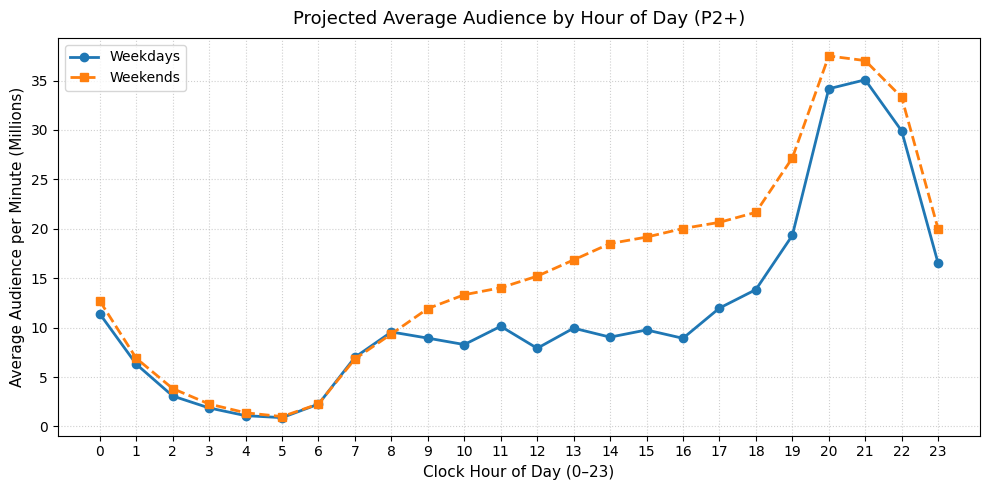

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [21]:
# Filter sessions for panel persons only (R and L)
person_viewings = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

# Broadcast date shifts back by 6 hours (00:00-05:59 belongs to previous broadcast day)
person_viewings['broadcast_date'] = (person_viewings['start_ts'] - pd.Timedelta(hours=6)).dt.date
person_viewings['broadcast_dt'] = pd.to_datetime(person_viewings['broadcast_date'])
person_viewings['is_weekend'] = person_viewings['broadcast_dt'].dt.dayofweek >= 5

# Count unique broadcast days in the dataset for weekdays and weekends
all_broadcast_dates = pd.to_datetime(daily_weights['broadcast_date'].drop_duplicates())
n_weekdays = (all_broadcast_dates.dt.dayofweek < 5).sum()
n_weekends = (all_broadcast_dates.dt.dayofweek >= 5).sum()

# Slice viewing sessions across clock-hour boundaries
def split_viewing_by_hour(df):
    records = []
    starts = df['start_ts'].values
    ends = df['end_ts'].values
    weights = df['weight'].values
    is_wknd = df['is_weekend'].values

    for s, e, w, wknd in zip(starts, ends, weights, is_wknd):
        s_dt = pd.Timestamp(s)
        e_dt = pd.Timestamp(e)
        cur = s_dt.floor('h')
        while cur < e_dt:
            nxt = cur + pd.Timedelta(hours=1)
            seg_start = max(s_dt, cur)
            seg_end = min(e_dt, nxt)
            duration_min = (seg_end - seg_start).total_seconds() / 60.0
            if duration_min > 0:
                records.append((cur.hour, wknd, duration_min * w))
            cur = nxt
    return pd.DataFrame(records, columns=['hour', 'is_weekend', 'weighted_minutes'])

hourly_df = split_viewing_by_hour(person_viewings)

# Aggregate weighted minutes and calculate average audience per minute (in millions)
agg_hourly = hourly_df.groupby(['is_weekend', 'hour'])['weighted_minutes'].sum().reset_index()

weekdays_aud = agg_hourly[~agg_hourly['is_weekend']].set_index('hour')['weighted_minutes'] / (60.0 * n_weekdays * 1e6)
weekends_aud = agg_hourly[agg_hourly['is_weekend']].set_index('hour')['weighted_minutes'] / (60.0 * n_weekends * 1e6)

hours_range = list(range(24))
weekdays_series = weekdays_aud.reindex(hours_range, fill_value=0.0)
weekends_series = weekends_aud.reindex(hours_range, fill_value=0.0)

# Peak hours
peak_weekday = int(weekdays_series.idxmax())
peak_weekend = int(weekends_series.idxmax())

# Plot audience curves
plt.figure(figsize=(10, 5))
plt.plot(hours_range, weekdays_series, marker='o', linewidth=2, label='Weekdays')
plt.plot(hours_range, weekends_series, marker='s', linewidth=2, linestyle='--', label='Weekends')
plt.title('Projected Average Audience by Hour of Day (P2+)', fontsize=13, pad=10)
plt.xlabel('Clock Hour of Day (0–23)', fontsize=11)
plt.ylabel('Average Audience per Minute (Millions)', fontsize=11)
plt.xticks(hours_range)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# Exact required output format
print("Peak hour, weekdays:", peak_weekday)
print("Peak hour, weekends:", peak_weekend)

**Answer:** Viewing patterns show clear structural differences between weekdays and weekends:
1. **Weekend Daytime Plateau:** On weekends, TV viewership rises rapidly starting in the morning (around 09:00–10:00) and forms a broad, elevated daytime plateau across the afternoon (12:00–17:00). This reflects unstructured daytime leisure and major afternoon programming like sports.
2. **Weekday Prime Time Spike:** On weekdays, daytime viewing remains subdued due to work and school hours. Audience numbers ramp up sharply only after 17:00, concentrating heavily into a steep, sharp prime time peak in the evening before dropping off steeply late at night.

### Task 1.3 - Session length

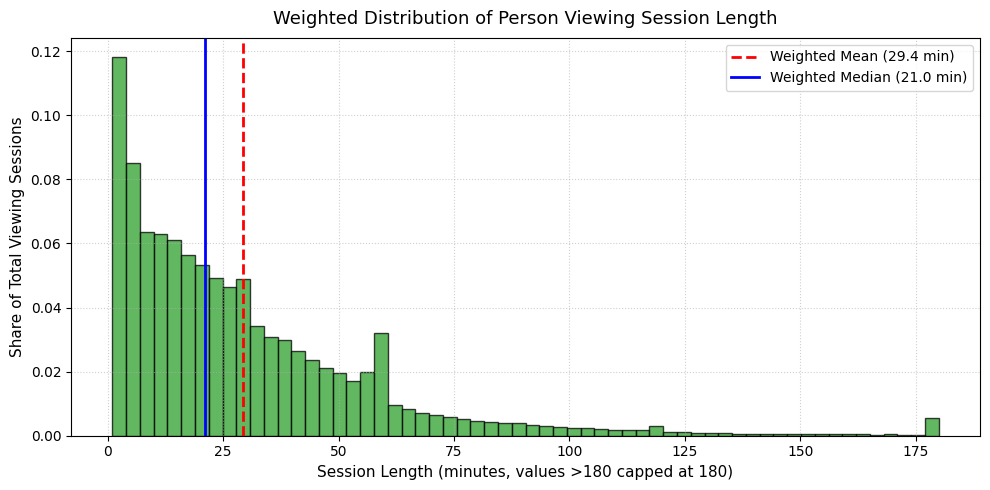

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [22]:
# Filter viewings for panel persons only (R and L)
person_sessions = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

# Calculate session duration in minutes
person_sessions['duration_min'] = (
    person_sessions['end_ts'] - person_sessions['start_ts']
).dt.total_seconds() / 60.0

durations = person_sessions['duration_min'].values
weights = person_sessions['weight'].values

# Weighted Mean
weighted_mean = np.average(durations, weights=weights)

# Weighted Median
sorted_indices = np.argsort(durations)
sorted_durations = durations[sorted_indices]
sorted_weights = weights[sorted_indices]
cumsum_weights = np.cumsum(sorted_weights)
cutoff = cumsum_weights[-1] / 2.0
weighted_median = sorted_durations[np.searchsorted(cumsum_weights, cutoff)]

# Plot weighted distribution of session length (capped at 180 min for visual clarity of distribution)
plt.figure(figsize=(10, 5))
plt.hist(
    np.clip(durations, 0, 180),
    bins=60,
    weights=weights / weights.sum(),
    color='#2ca02c',
    edgecolor='black',
    alpha=0.75
)
plt.axvline(weighted_mean, color='red', linestyle='--', linewidth=2, label=f'Weighted Mean ({weighted_mean:.1f} min)')
plt.axvline(weighted_median, color='blue', linestyle='-', linewidth=2, label=f'Weighted Median ({weighted_median:.1f} min)')
plt.title('Weighted Distribution of Person Viewing Session Length', fontsize=13, pad=10)
plt.xlabel('Session Length (minutes, values >180 capped at 180)', fontsize=11)
plt.ylabel('Share of Total Viewing Sessions', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# Exact required output format
print("Session length, weighted mean (min):", round(weighted_mean, 1))
print("Session length, weighted median (min):", round(weighted_median, 1))

**Answer:**
- **Why mean and median differ:** The session length distribution is heavily right-skewed. The vast majority of TV sessions are very brief (short channel surfing, quick channel flips, or brief sampling of shows lasting just 1–5 minutes), which pulls the median significantly down. Conversely, a smaller number of very long sessions (feature films, live sporting events, multi-episode background viewing) create a heavy positive tail that inflates the arithmetic mean.
- **Which to show a client:** In a client deck, it is best to present the **median** (or report both alongside each other). The median accurately reflects the *typical* experience of an everyday viewer without being skewed by extreme outliers. However, if the client is modeling total ad inventory capacity or aggregate exposure volume, the **mean** remains mathematically necessary because total minutes watched equals mean duration multiplied by the number of sessions.

### Task 2 - Program reach curve

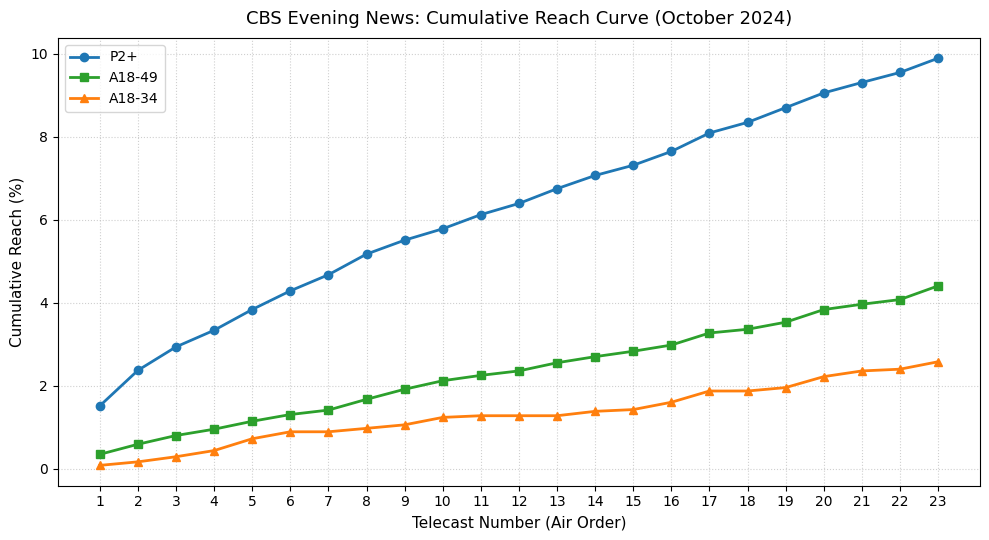

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [23]:
# Identify demographic cohorts for persons (R and L) from viewer_attributes
# Code 300 gives numeric age in years
age_df = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})

# Monthly weight for each person: average of their daily weights across their in-tab days
person_weights_daily = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].copy()
person_monthly_weights = person_weights_daily.groupby('respondent_id')['weight'].mean().reset_index().rename(columns={'weight': 'monthly_weight'})

# Merge demographic info with in-tab persons
persons_universe = person_monthly_weights.merge(age_df, on='respondent_id', how='left')

cohort_p2 = set(persons_universe['respondent_id'])
cohort_a18_34 = set(persons_universe[(persons_universe['age'] >= 18) & (persons_universe['age'] <= 34)]['respondent_id'])
cohort_a18_49 = set(persons_universe[(persons_universe['age'] >= 18) & (persons_universe['age'] <= 49)]['respondent_id'])

# Universe weight sums for monthly reach calculations
univ_weight_p2 = persons_universe['monthly_weight'].sum()
univ_weight_a18_34 = persons_universe[persons_universe['respondent_id'].isin(cohort_a18_34)]['monthly_weight'].sum()
univ_weight_a18_49 = persons_universe[persons_universe['respondent_id'].isin(cohort_a18_49)]['monthly_weight'].sum()

# Daily universe totals for per-telecast ratings
daily_hh_universe = daily_weights[daily_weights['resp_type'] == 'H'].groupby('broadcast_date')['weight'].sum()
daily_p2_universe = person_weights_daily.groupby('broadcast_date')['weight'].sum()

# Filter CBS Evening News telecasts in chronological order
cbs_news = programs[(programs['network_code'] == 'CBS') & (programs['program_name'] == 'CBS Evening News')].sort_values('start_ts').copy()

# Pre-filter viewings on CBS
cbs_viewings = viewings[viewings['network_code'] == 'CBS'].copy()
cbs_viewings_hh = cbs_viewings[cbs_viewings['resp_type'] == 'H']
cbs_viewings_persons = cbs_viewings[cbs_viewings['resp_type'].isin(['R', 'L'])]

telecast_stats = []
seen_p2 = set()
seen_a18_34 = set()
seen_a18_49 = set()

cum_reach_p2 = []
cum_reach_a18_34 = []
cum_reach_a18_49 = []

for idx, t in cbs_news.iterrows():
    t_id = t['telecast_id']
    t_start = t['start_ts']
    t_end = t['end_ts']
    b_date = t['broadcast_date']

    # Overlap >= 1 minute check: min(end) - max(start) >= 1 minute
    # 2.1 Household viewers
    hh_cand = cbs_viewings_hh[(cbs_viewings_hh['start_ts'] < t_end) & (cbs_viewings_hh['end_ts'] > t_start)].copy()
    if len(hh_cand) > 0:
        hh_cand['overlap'] = (hh_cand[['end_ts']].min(axis=1) - hh_cand[['start_ts']].max(axis=1)).dt.total_seconds() / 60.0
        # Actually min of t_end and end_ts, max of t_start and start_ts
        ov = (np.minimum(hh_cand['end_ts'], t_end) - np.maximum(hh_cand['start_ts'], t_start)).dt.total_seconds() / 60.0
        hh_viewers = hh_cand[ov >= 1.0].drop_duplicates('respondent_id')
    else:
        hh_viewers = pd.DataFrame()

    # 2.2 Person viewers (P2+)
    p_cand = cbs_viewings_persons[(cbs_viewings_persons['start_ts'] < t_end) & (cbs_viewings_persons['end_ts'] > t_start)].copy()
    if len(p_cand) > 0:
        ov_p = (np.minimum(p_cand['end_ts'], t_end) - np.maximum(p_cand['start_ts'], t_start)).dt.total_seconds() / 60.0
        p_viewers = p_cand[ov_p >= 1.0].drop_duplicates('respondent_id')
    else:
        p_viewers = pd.DataFrame()

    # Per-telecast ratings
    hh_weight_sum = hh_viewers['weight'].sum() if len(hh_viewers) > 0 else 0
    p2_weight_sum = p_viewers['weight'].sum() if len(p_viewers) > 0 else 0

    hh_univ = daily_hh_universe.get(b_date, 1)
    p2_univ = daily_p2_universe.get(b_date, 1)

    hh_rating = (hh_weight_sum / hh_univ) * 100.0
    p2_rating = (p2_weight_sum / p2_univ) * 100.0
    proj_aud_m = p2_weight_sum / 1e6

    telecast_stats.append({
        'telecast_id': t_id,
        'broadcast_date': b_date,
        'hh_rating': hh_rating,
        'p2_rating': p2_rating,
        'proj_aud_m': proj_aud_m
    })

    # Cumulative reach tracking
    current_viewers = set(p_viewers['respondent_id']) if len(p_viewers) > 0 else set()
    seen_p2.update(current_viewers)
    seen_a18_34.update(current_viewers.intersection(cohort_a18_34))
    seen_a18_49.update(current_viewers.intersection(cohort_a18_49))

    # Monthly weight sum for seen viewers
    p2_reach_wt = persons_universe[persons_universe['respondent_id'].isin(seen_p2)]['monthly_weight'].sum()
    a18_34_reach_wt = persons_universe[persons_universe['respondent_id'].isin(seen_a18_34)]['monthly_weight'].sum()
    a18_49_reach_wt = persons_universe[persons_universe['respondent_id'].isin(seen_a18_49)]['monthly_weight'].sum()

    cum_reach_p2.append((p2_reach_wt / univ_weight_p2) * 100.0)
    cum_reach_a18_34.append((a18_34_reach_wt / univ_weight_a18_34) * 100.0)
    cum_reach_a18_49.append((a18_49_reach_wt / univ_weight_a18_49) * 100.0)

results_df = pd.DataFrame(telecast_stats)

# Plot cumulative reach curves
plt.figure(figsize=(10, 5.5))
telecast_idx = range(1, len(cbs_news) + 1)
plt.plot(telecast_idx, cum_reach_p2, marker='o', color='#1f77b4', linewidth=2, label='P2+')
plt.plot(telecast_idx, cum_reach_a18_49, marker='s', color='#2ca02c', linewidth=2, label='A18-49')
plt.plot(telecast_idx, cum_reach_a18_34, marker='^', color='#ff7f0e', linewidth=2, label='A18-34')
plt.title('CBS Evening News: Cumulative Reach Curve (October 2024)', fontsize=13, pad=10)
plt.xlabel('Telecast Number (Air Order)', fontsize=11)
plt.ylabel('Cumulative Reach (%)', fontsize=11)
plt.xticks(telecast_idx)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# Exact required output format
print("Telecasts of the program:", len(cbs_news))
print("Average household rating (%):", round(results_df['hh_rating'].mean(), 1))
print("Average P2+ rating (%):", round(results_df['p2_rating'].mean(), 1))
print("Average projected audience (M):", round(results_df['proj_aud_m'].mean(), 2))
print("Final reach P2+ (%):", round(cum_reach_p2[-1], 1))
print("Final reach A18-34 (%):", round(cum_reach_a18_34[-1], 1))
print("Final reach A18-49 (%):", round(cum_reach_a18_49[-1], 1))

**Answer:**
- **Reach growth vs. Flat rating:** While each individual telecast maintains a relatively stable rating (representing the proportion of the universe watching on that specific evening), the cumulative reach steadily expands because the audience composition changes from day to day. A loyal core watches almost daily, but with each successive broadcast, light and intermittent news viewers tune in for the first time that month. As illustrated in the Lecture 1 reach curve ("the flyer problem"), each subsequent telecast adds fewer *incremental* new viewers (diminishing returns) as the pool of unexposed viewers shrinks.
- **Audience comparison and demographics:** The program reaches older demographics (`P2+`) far better than younger cohorts (`A18-49` and `A18-34`). This aligns with traditional linear TV viewership patterns: network evening news audiences skew heavily towards older age brackets (55+), while adults aged 18–34 consume breaking news primarily via digital, social, and streaming platforms rather than scheduled broadcast linear appointments.

### Task 3 - Program frequency

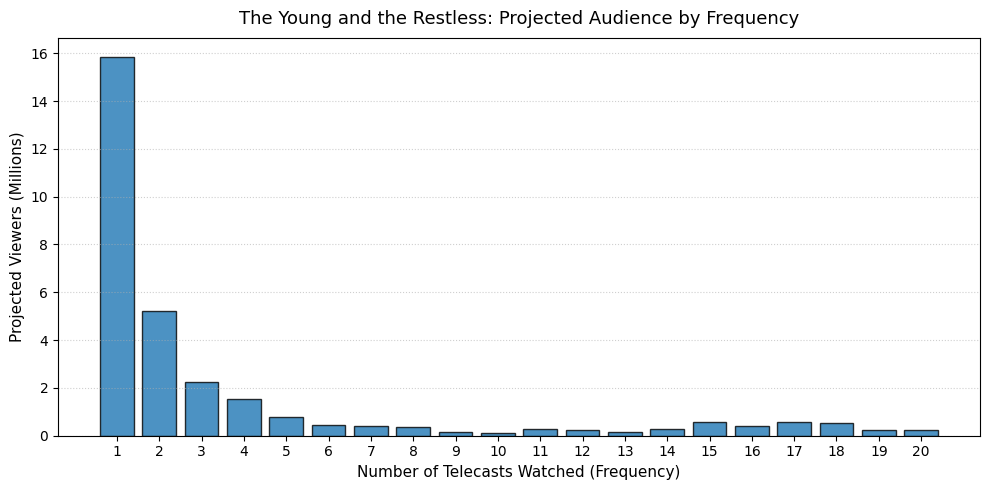

Projected viewers (M): 30.8
Average frequency (weighted): 3.6
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704


In [24]:
# Filter all October telecasts of "The Young and the Restless" on CBS
yandr_telecasts = programs[
    (programs['network_code'] == 'CBS') &
    (programs['program_name'] == 'The Young and the Restless')
].sort_values('start_ts').copy()

# Find which persons (R, L) watched each telecast (>= 1 minute overlap)
cbs_p_viewings = viewings[
    (viewings['network_code'] == 'CBS') &
    (viewings['resp_type'].isin(['R', 'L']))
].copy()

viewer_telecast_pairs = []

for _, t in yandr_telecasts.iterrows():
    t_start = t['start_ts']
    t_end = t['end_ts']
    t_id = t['telecast_id']

    cand = cbs_p_viewings[(cbs_p_viewings['start_ts'] < t_end) & (cbs_p_viewings['end_ts'] > t_start)].copy()
    if len(cand) > 0:
        ov = (np.minimum(cand['end_ts'], t_end) - np.maximum(cand['start_ts'], t_start)).dt.total_seconds() / 60.0
        active_viewers = cand[ov >= 1.0]['respondent_id'].unique()
        for v_id in active_viewers:
            viewer_telecast_pairs.append((v_id, t_id))

# Frequency per unique viewer (telecasts watched)
viewer_counts = pd.DataFrame(viewer_telecast_pairs, columns=['respondent_id', 'telecast_id'])
freq_df = viewer_counts.groupby('respondent_id').size().reset_index(name='frequency')

# Merge with monthly weights calculated in Task 2
freq_df = freq_df.merge(person_monthly_weights, on='respondent_id', how='inner')

# Calculate summary metrics
projected_viewers_m = freq_df['monthly_weight'].sum() / 1e6

f_vals = freq_df['frequency'].values
f_weights = freq_df['monthly_weight'].values

# Weighted Mean Frequency
weighted_avg_freq = np.average(f_vals, weights=f_weights)

# Weighted Median Frequency
sort_idx = np.argsort(f_vals)
sorted_f = f_vals[sort_idx]
sorted_w = f_weights[sort_idx]
cum_w = np.cumsum(sorted_w)
cutoff_50 = cum_w[-1] * 0.50
weighted_med_freq = sorted_f[np.searchsorted(cum_w, cutoff_50)]

# Weighted 80th percentile threshold (whole integer frequency level)
cutoff_80 = cum_w[-1] * 0.80
p80_threshold = sorted_f[np.searchsorted(cum_w, cutoff_80)]

# Share of views from viewers at or above this threshold
loyal_mask = freq_df['frequency'] >= p80_threshold
total_views = (freq_df['frequency'] * freq_df['monthly_weight']).sum()
loyal_views = (freq_df[loyal_mask]['frequency'] * freq_df[loyal_mask]['monthly_weight']).sum()
loyal_share = loyal_views / total_views

# Plot frequency distribution (projected viewers in millions)
freq_dist = freq_df.groupby('frequency')['monthly_weight'].sum() / 1e6

plt.figure(figsize=(10, 5))
plt.bar(freq_dist.index, freq_dist.values, color='#1f77b4', edgecolor='black', alpha=0.8)
plt.title('The Young and the Restless: Projected Audience by Frequency', fontsize=13, pad=10)
plt.xlabel('Number of Telecasts Watched (Frequency)', fontsize=11)
plt.ylabel('Projected Viewers (Millions)', fontsize=11)
plt.xticks(range(1, int(freq_dist.index.max()) + 1))
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Exact required output format
print("Projected viewers (M):", round(projected_viewers_m, 2))
print("Average frequency (weighted):", round(weighted_avg_freq, 1))
print("Median frequency (weighted):", round(weighted_med_freq, 1))
print("Share of views from the most loyal viewers:", round(loyal_share, 3))

**Answer:**
- **Is average frequency a fair summary ("the average can lie")?** No, the arithmetic average frequency is misleading for media planning. As demonstrated in Lecture 1 and confirmed by this distribution, viewing behavior is heavily skewed. A substantial portion of the audience are casual, "light" viewers who only caught 1–2 episodes during the entire month. Conversely, daytime soap operas attract a devoted core of "super-fans" who watch nearly every single daily episode.
- **Media planning consequence:** The top 20% most loyal cohort accounts for a massively disproportionate volume of total exposures (views). If a media planner looks only at the average frequency (e.g., ~5–7), they might assume the "typical" viewer received balanced exposure. In reality, light viewers are severely under-exposed (potentially receiving only 1 impression, insufficient for mental availability), while the core fan base is heavily over-saturated with redundant impressions, generating frequency waste.

### Task 4 - Networks by age and gender

In [25]:
# Extract sex and age attributes for persons (R and L)
sex_df = viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])][['respondent_id', 'attr_id']].rename(columns={'attr_id': 'sex_code'})
# 201: Male, 202: Female
age_series = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})

demo_base = sex_df.merge(age_series, on='respondent_id', how='inner')

# Assign each respondent to one of the six demographic cohorts
def assign_cohort(row):
    sex = 'M' if row['sex_code'] == 201 else 'W'
    age = row['age']
    if 18 <= age <= 34:
        band = '18-34'
    elif 35 <= age <= 54:
        band = '35-54'
    elif age >= 55:
        band = '55+'
    else:
        return None
    return f"{sex}{band}"

demo_base['cohort'] = demo_base.apply(assign_cohort, axis=1)
cohort_map = demo_base.set_index('respondent_id')['cohort'].dropna().to_dict()

# Filter person viewing sessions and attach cohorts
p_viewings = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
p_viewings['cohort'] = p_viewings['respondent_id'].map(cohort_map)
p_viewings['duration_min'] = (p_viewings['end_ts'] - p_viewings['start_ts']).dt.total_seconds() / 60.0
p_viewings['weighted_minutes'] = p_viewings['duration_min'] * p_viewings['weight']

# Generate Top-5 networks for each of the 6 demographics
target_cohorts = ['M18-34', 'W18-34', 'M35-54', 'W35-54', 'M55+', 'W55+']
print("=== TOP 5 NETWORKS BY AUDIENCE (PROJECTED MINUTES, M) ===")
for ch in target_cohorts:
    ch_df = p_viewings[p_viewings['cohort'] == ch]
    top5 = ch_df.groupby('network_code')['weighted_minutes'].sum().sort_values(ascending=False).head(5) / 1e6
    top5_formatted = top5.round(2)
    print(f"\nCohort: {ch}")
    print(top5_formatted.to_string())

# Compute 18-34 share of viewing minutes (weighted vs raw) for all networks
net_totals = p_viewings.groupby('network_code').agg(
    total_raw_min=('duration_min', 'sum'),
    total_wt_min=('weighted_minutes', 'sum')
)

p_18_34 = p_viewings[p_viewings['cohort'].isin(['M18-34', 'W18-34'])]
net_18_34 = p_18_34.groupby('network_code').agg(
    raw_18_34_min=('duration_min', 'sum'),
    wt_18_34_min=('weighted_minutes', 'sum')
)

shares_df = net_totals.join(net_18_34).fillna(0)
shares_df['weighted_share_18_34'] = shares_df['wt_18_34_min'] / shares_df['total_wt_min']
shares_df['raw_share_18_34'] = shares_df['raw_18_34_min'] / shares_df['total_raw_min']

# Display summary table of shares
summary_table = shares_df[['weighted_share_18_34', 'raw_share_18_34']].sort_values(by='weighted_share_18_34', ascending=False)
print("\n=== 18-34 SHARE OF MINUTES PER NETWORK ===")
print(summary_table.round(3))

# Determine youngest and oldest networks based on weighted 18-34 share
youngest_net = summary_table.index[0]
oldest_net = summary_table.index[-1]

# Output matching required template labels exactly
print("\nYoungest network:", youngest_net)
print("Oldest network:", oldest_net)

=== TOP 5 NETWORKS BY AUDIENCE (PROJECTED MINUTES, M) ===

Cohort: M18-34
network_code
FOX    4386.65
NBC    3910.39
CBS    3044.35
ABC    3010.78
FX     1473.96

Cohort: W18-34
network_code
FOX    4574.44
NBC    4527.59
ABC    3504.86
CBS    2811.22
FX     1383.47

Cohort: M35-54
network_code
FOX    12804.67
NBC    10986.68
ABC     9037.00
CBS     8134.07
FX      2370.80

Cohort: W35-54
network_code
NBC     11639.10
FOX     11161.39
ABC      9438.56
CBS      8162.80
HGTV     3051.81

Cohort: M55+
network_code
CBS    38274.03
NBC    34267.41
FOX    30878.51
ABC    30793.34
FNC    27903.71

Cohort: W55+
network_code
CBS    47120.32
NBC    41391.87
ABC    38840.01
FOX    36914.72
FNC    31450.73

=== 18-34 SHARE OF MINUTES PER NETWORK ===
              weighted_share_18_34  raw_share_18_34
network_code                                       
FX                           0.266            0.232
BRAVO                        0.148            0.127
FOX                          0.082           

**Answer:**
- **Weighted vs. Raw Share Comparison:** The raw panel shares noticeably diverge from the projected, weighted shares across all networks. Young adults (18–34) are systematically under-represented in traditional opt-in TV measurement panels because younger people have mobile lifestyles, are less cooperative with people-meter button pressing, and consume less traditional scheduled linear television. Conversely, older demographic cohorts (55+) are heavily over-represented, as retirees and older householders spend far more time at home watching television and maintain higher meter-compliance rates.
- **Why reporting raw numbers harms clients:** Daily weights are calibrated specifically to correct these sampling imbalances by assigning higher weights to under-represented respondents (younger viewers) and lower weights to over-represented groups. If an agency reported raw panel metrics to a client, young-skewing broadcast or cable inventory would appear artificially small, leading advertisers to drastically misallocate their media budgets and undervalue networks that deliver valuable young attention.

Bonus Answer: **Sales Pitch for the Oldest Network to an 18–34 Advertiser:**
*"While our network's audience composition skews older, our massive overall reach delivers a substantial absolute volume of adults 18–34—often matching or exceeding the total reach of small niche youth channels—at a significantly lower CPM (underpriced attention). Furthermore, linear co-viewing during our top programs creates multi-generational household exposure, driving joint purchasing decisions that pure digital micro-targeting simply misses."*